# Milestone 3: Data Processing, EDA and Parameter Estimation

**Data:** daily prices of the 11 SPDR sector ETFs and SPY (benchmark) from Yahoo Finance, Dec 1, 2023 to Sep 30, 2026.

**Steps**
1. Data collection
2. Preprocessing (cleaning checks, corporate actions, monthly returns)
3. Exploratory data analysis
4. Parameter estimation for the mean-variance model ($\mu_i$, $\sigma_{ij}$)

In [1]:
# !pip install yfinance   # uncomment if running in Colab

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import yfinance as yf

SECTORS = ["XLC", "XLY", "XLP", "XLE", "XLF", "XLV", "XLI", "XLB", "XLRE", "XLK", "XLU"]
TICKERS = SECTORS + ["SPY"]

R_MIN = 0.20   # minimum expected annual return
C_MAX = 0.20   # sector cap

DATA_FILE = "data/etf_prices_daily.xlsx"

## 1. Data collection

We download daily Close, Adjusted Close, Dividends and Stock Splits with `yfinance`. The download is saved once to `data/etf_prices_daily.xlsx` and every later step reads from that file, so the results don't change if Yahoo revises its data.

We start on Dec 1, 2023 because the January 2024 return needs the December 2023 month-end price.

In [2]:
if not os.path.exists(DATA_FILE):
    frames = []
    for t in TICKERS:
        h = yf.Ticker(t).history(start="2023-12-01", end="2026-10-01", auto_adjust=False, actions=True)
        h.index = h.index.tz_localize(None).normalize()
        h["Ticker"] = t
        frames.append(h[["Ticker", "Close", "Adj Close", "Dividends", "Stock Splits"]])
    raw = pd.concat(frames).reset_index().rename(columns={"index": "Date"})
    os.makedirs("data", exist_ok=True)
    raw.to_excel(DATA_FILE, index=False)

raw = pd.read_excel(DATA_FILE, parse_dates=["Date"])
print(raw.shape)
raw.head()

(8508, 6)


,Date,Ticker,Close,Adj Close,Dividends,Stock Splits
0,2023-12-01,XLC,69.910004,67.533134,0.0,0
1,2023-12-04,XLC,69.209999,66.856918,0.0,0
2,2023-12-05,XLC,68.889999,66.547798,0.0,0
3,2023-12-06,XLC,68.709999,66.373909,0.0,0
4,2023-12-07,XLC,70.150002,67.764969,0.0,0


## 2. Preprocessing

### 2.1 Data quality checks

In [3]:
print("Missing values:\n", raw.isna().sum(), "\n")
print("Duplicate (Date, Ticker) rows:", raw.duplicated(["Date", "Ticker"]).sum())
print("Non-positive prices:", (raw[["Close", "Adj Close"]] <= 0).sum().sum())

# every ticker should have the same trading days
days = raw.groupby("Ticker")["Date"].agg(["count", "min", "max"])
days

Missing values:
 Date            0
Ticker          0
Close           0
Adj Close       0
Dividends       0
Stock Splits    0
dtype: int64 

Duplicate (Date, Ticker) rows: 0
Non-positive prices: 0


,count,min,max
Ticker,,,
SPY,709,2023-12-01,2026-09-30
XLB,709,2023-12-01,2026-09-30
XLC,709,2023-12-01,2026-09-30
XLE,709,2023-12-01,2026-09-30
XLF,709,2023-12-01,2026-09-30
XLI,709,2023-12-01,2026-09-30
XLK,709,2023-12-01,2026-09-30
XLP,709,2023-12-01,2026-09-30
XLRE,709,2023-12-01,2026-09-30


No missing values, no duplicates, and all 12 tickers have the same 709 trading days, so nothing needs to be filled or dropped.

### 2.2 Corporate actions: splits and dividends

In [4]:
raw[raw["Stock Splits"] > 0][["Date", "Ticker", "Stock Splits"]]

,Date,Ticker,Stock Splits
1213,2025-12-05,XLY,2
2631,2025-12-05,XLE,2
5467,2025-12-05,XLB,2
6885,2025-12-05,XLK,2
7594,2025-12-05,XLU,2


In [5]:
# Check that the split doesn't show up as a fake -50% move in the price series
close = raw.pivot(index="Date", columns="Ticker", values="Close")[TICKERS]
adj   = raw.pivot(index="Date", columns="Ticker", values="Adj Close")[TICKERS]

split_day = pd.Timestamp("2025-12-05")
close.pct_change().loc[split_day, ["XLY", "XLE", "XLB", "XLK", "XLU"]].round(4)

Ticker
XLY    0.0055
XLE   -0.0041
XLB   -0.0033
XLK    0.0073
XLU   -0.0094
Name: 2025-12-05 00:00:00, dtype: float64

Five ETFs had a 2-for-1 split on Dec 5, 2025. Yahoo's Close is already split-adjusted, so the daily change that day is normal.

Next we check how much dividends matter, by comparing the total return (Adjusted Close) against the price-only return (Close) over 2024-2025.

In [6]:
me_adj, me_close = adj.resample("ME").last(), close.resample("ME").last()
total = me_adj.loc["2025-12"].iloc[0] / me_adj.loc["2023-12"].iloc[0] - 1
price = me_close.loc["2025-12"].iloc[0] / me_close.loc["2023-12"].iloc[0] - 1

div_effect = pd.DataFrame({"total return": total, "price return": price, "dividend effect": total - price})
(div_effect * 100).round(2).sort_values("dividend effect", ascending=False)

,total return,price return,dividend effect
Ticker,,,
XLU,43.07,34.82,8.25
XLE,13.87,6.66,7.22
XLRE,7.86,0.72,7.13
XLP,13.90,7.84,6.06
XLF,50.01,45.66,4.35
XLB,10.11,6.03,4.08
XLI,40.01,36.08,3.92
XLV,17.34,13.51,3.83
XLC,65.79,62.01,3.78


Dividends add about 2% (XLK) to 8% (XLU) over two years, and for XLRE they are almost all of the return. **So we use Adjusted Close for all returns.**

### 2.3 Monthly returns

$P_{i,t}$ = Adjusted Close on the last trading day of month $t$, and $r_{it} = P_{i,t}/P_{i,t-1} - 1$.

- **Estimation window:** Jan 2024 to Dec 2025 ($T = 24$), used to estimate the parameters
- **Evaluation window:** Jan to Sep 2026, held out to test the portfolio later

In [7]:
monthly_ret = me_adj.pct_change().dropna()
monthly_ret.index = monthly_ret.index.to_period("M")

est = monthly_ret.loc["2024-01":"2025-12"]
oos = monthly_ret.loc["2026-01":"2026-09"]
print("Estimation months:", len(est), " | Evaluation months:", len(oos))
(est * 100).round(2).head()

Estimation months: 24  | Evaluation months: 9


Ticker,XLC,XLY,XLP,XLE,XLF,XLV,XLI,XLB,XLRE,XLK,XLU,SPY
Date,,,,,,,,,,,,
2024-01,4.43,-4.41,1.24,-0.51,3.09,2.93,-0.97,-3.89,-4.82,2.70,-2.97,1.59
2024-02,4.59,7.89,2.10,3.27,4.08,3.16,7.18,6.51,2.57,4.70,1.06,5.22
2024-03,3.18,-0.06,3.32,10.49,4.81,2.38,4.42,6.47,1.76,0.79,6.59,3.27
2024-04,-4.65,-4.50,-1.13,-0.94,-4.18,-5.01,-3.52,-4.59,-8.45,-5.76,1.66,-4.03
2024-05,6.94,0.20,2.44,-0.34,3.17,2.40,1.64,3.27,5.14,7.08,8.96,5.06


## 3. Exploratory data analysis

### 3.1 Summary statistics (estimation window)

In [8]:
eda = pd.DataFrame({
    "mean (%/mo)": est.mean() * 100,
    "std (%/mo)": est.std() * 100,
    "min (%)": est.min() * 100,
    "max (%)": est.max() * 100,
    "skew": est.skew(),
    "excess kurtosis": est.kurt(),
    "JB p-value": [stats.jarque_bera(est[t]).pvalue for t in TICKERS],
    "lag-1 autocorr": [est[t].autocorr(1) for t in TICKERS],
    "corr w/ SPY": est.corrwith(est["SPY"]),
})
eda.round(2)

,mean (%/mo),std (%/mo),min (%),max (%),skew,excess kurtosis,JB p-value,lag-1 autocorr,corr w/ SPY
Ticker,,,,,,,,,
XLC,2.19,3.69,-5.16,7.29,-0.40,-0.72,0.54,-0.16,0.84
XLY,1.40,4.88,-8.31,12.91,0.18,0.50,0.93,-0.04,0.75
XLP,0.58,2.74,-4.82,5.99,0.11,-0.43,0.82,-0.27,0.30
XLE,0.66,4.96,-13.86,10.49,-1.06,2.95,0.01,-0.18,0.34
XLF,1.77,3.82,-5.46,10.46,-0.04,-0.03,0.96,-0.30,0.66
XLV,0.75,4.09,-6.25,9.29,-0.03,-0.56,0.79,-0.02,0.33
XLI,1.48,3.89,-8.03,8.84,-0.22,0.37,0.92,-0.31,0.80
XLB,0.49,4.30,-10.76,6.51,-0.65,0.28,0.48,-0.33,0.53
XLRE,0.40,4.07,-8.65,7.24,-0.68,0.28,0.45,-0.21,0.56


**Observations**
- XLC, XLK and XLF had the highest average returns. XLP had the lowest volatility (about 2.7% per month) and XLE the highest.
- Skew and kurtosis are small for most ETFs. The Jarque-Bera test rejects normality at 5% only for XLE, which has a fat left tail (one -13.9% month, excess kurtosis ≈ 3). For the rest, variance is a reasonable risk measure, although with 24 points the test has low power.
- Lag-1 autocorrelations range from -0.37 to 0.14. With $T = 24$ the standard error is about $1/\sqrt{24} \approx 0.2$, so none is clearly significant. This roughly supports the "independent across months" assumption behind scaling by 12, but most are slightly negative, so the √12 scaling may slightly overstate annual volatility.

### 3.2 Distribution of monthly returns

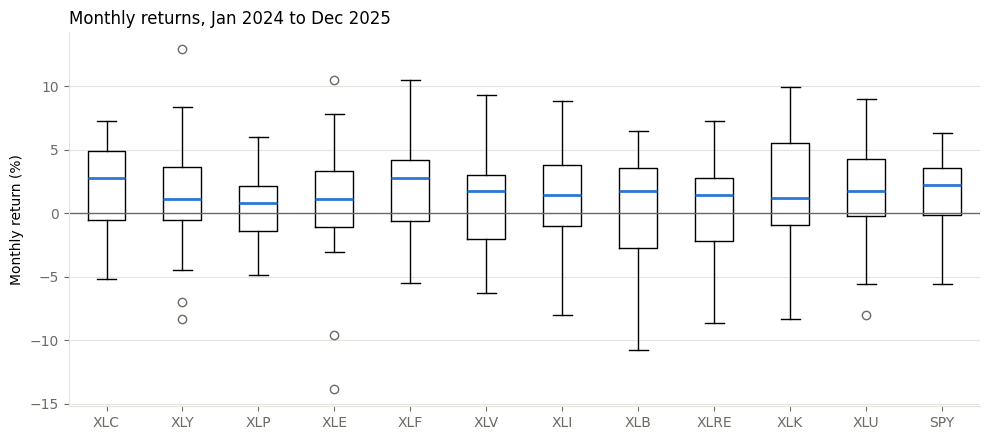

In [9]:
INK, MUTED, GRID, BLUE, ORANGE = "#1f1f1e", "#6b6a63", "#e4e3de", "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([est[t] * 100 for t in TICKERS], tick_labels=TICKERS, widths=0.5,
           medianprops=dict(color=BLUE, linewidth=2), flierprops=dict(markeredgecolor=MUTED))
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylabel("Monthly return (%)")
ax.set_title("Monthly returns, Jan 2024 to Dec 2025", loc="left")
ax.grid(axis="y", color=GRID)
plt.tight_layout(); plt.show()

### 3.3 Risk vs. return

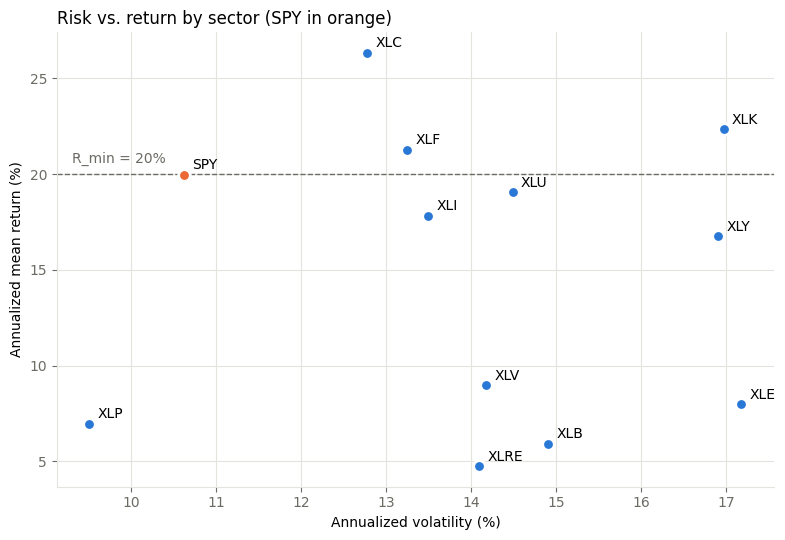

In [10]:
mu_all  = 12 * est.mean() * 100
vol_all = np.sqrt(12) * est.std() * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(vol_all[SECTORS], mu_all[SECTORS], s=70, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
ax.scatter(vol_all["SPY"], mu_all["SPY"], s=70, color=ORANGE, edgecolor="white", linewidth=2, zorder=3)
for t in TICKERS:
    ax.annotate(t, (vol_all[t], mu_all[t]), xytext=(6, 4), textcoords="offset points")
ax.axhline(R_MIN * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(9.3, R_MIN * 100 + 0.6, "R_min = 20%", color=MUTED)
ax.set_xlabel("Annualized volatility (%)"); ax.set_ylabel("Annualized mean return (%)")
ax.set_title("Risk vs. return by sector (SPY in orange)", loc="left")
ax.grid(color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

Only four sector ETFs (XLC, XLK, XLF, XLU) are at or close to the 20% line. SPY alone has a lower volatility than every sector except XLP, which shows how much diversification across sectors reduces risk.

### 3.4 Correlations

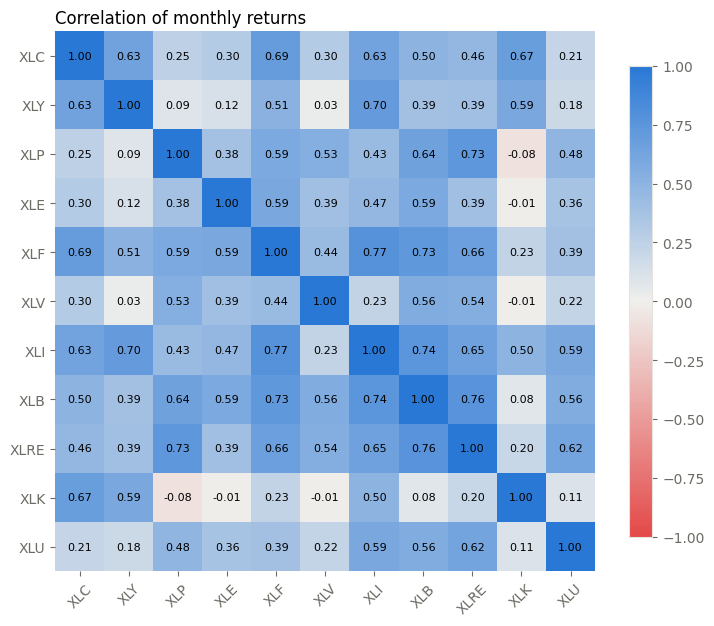

In [11]:
from matplotlib.colors import LinearSegmentedColormap
corr = est[SECTORS].corr()
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", BLUE])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(11), SECTORS, rotation=45); ax.set_yticks(range(11), SECTORS)
for i in range(11):
    for j in range(11):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.spines[:].set_visible(False)
ax.set_title("Correlation of monthly returns", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

XLK has close to zero correlation with XLP, XLE and XLV, while the cyclical sectors (XLF, XLI, XLB) move together (0.7+). The optimizer will reduce risk by pairing Technology with these defensive sectors.

### 3.5 In-sample vs. 2026

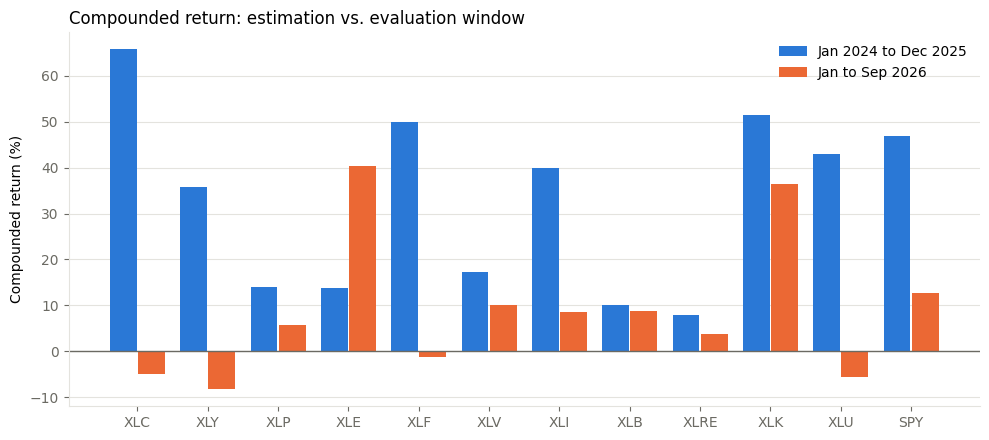

In [12]:
comp = pd.DataFrame({"Jan 2024 to Dec 2025": (1 + est).prod() - 1,
                     "Jan to Sep 2026": (1 + oos).prod() - 1}) * 100
x = np.arange(len(TICKERS))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - 0.2, comp.iloc[:, 0], 0.38, color=BLUE, label=comp.columns[0])
ax.bar(x + 0.2, comp.iloc[:, 1], 0.38, color=ORANGE, label=comp.columns[1])
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(x, TICKERS); ax.set_ylabel("Compounded return (%)")
ax.set_title("Compounded return: estimation vs. evaluation window", loc="left")
ax.legend(frameon=False); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

The leaders of 2024-25 did not stay on top: XLC and XLU are negative so far in 2026, while XLE, one of the weakest in-sample, is up about 40%. Mean returns estimated from 24 months are noisy, which we should keep in mind when interpreting the optimal weights.

## 4. Parameter estimation

$$\bar r_i = \frac{1}{24}\sum_{t=1}^{24} r_{it}, \qquad \mu_i = 12\,\bar r_i, \qquad \sigma_{ij} = 12\,\widehat{\mathrm{Cov}}(r_{it}, r_{jt})$$

In [13]:
mu  = 12 * est[SECTORS].mean()
cov = 12 * est[SECTORS].cov()

params = pd.DataFrame({"r_bar (%)": est[SECTORS].mean() * 100,
                       "mu (%)": mu * 100,
                       "volatility (%)": np.sqrt(np.diag(cov)) * 100})
params.round(2).sort_values("mu (%)", ascending=False)

,r_bar (%),mu (%),volatility (%)
Ticker,,,
XLC,2.19,26.32,12.77
XLK,1.86,22.33,16.97
XLF,1.77,21.28,13.24
XLU,1.59,19.05,14.49
XLI,1.48,17.81,13.49
XLY,1.40,16.76,16.90
XLV,0.75,8.98,14.17
XLE,0.66,7.97,17.18
XLP,0.58,6.96,9.51


In [14]:
cov.round(4)

Ticker,XLC,XLY,XLP,XLE,XLF,XLV,XLI,XLB,XLRE,XLK,XLU
Ticker,,,,,,,,,,,
XLC,0.0163,0.0137,0.0031,0.0067,0.0117,0.0054,0.0109,0.0095,0.0084,0.0146,0.0040
XLY,0.0137,0.0286,0.0014,0.0035,0.0114,0.0006,0.0159,0.0097,0.0094,0.0170,0.0045
XLP,0.0031,0.0014,0.0090,0.0061,0.0074,0.0072,0.0055,0.0091,0.0098,-0.0014,0.0066
XLE,0.0067,0.0035,0.0061,0.0295,0.0134,0.0096,0.0108,0.0150,0.0096,-0.0003,0.0090
XLF,0.0117,0.0114,0.0074,0.0134,0.0175,0.0082,0.0138,0.0143,0.0124,0.0052,0.0075
XLV,0.0054,0.0006,0.0072,0.0096,0.0082,0.0201,0.0044,0.0118,0.0108,-0.0002,0.0046
XLI,0.0109,0.0159,0.0055,0.0108,0.0138,0.0044,0.0182,0.0150,0.0124,0.0114,0.0116
XLB,0.0095,0.0097,0.0091,0.0150,0.0143,0.0118,0.0150,0.0222,0.0159,0.0019,0.0120
XLRE,0.0084,0.0094,0.0098,0.0096,0.0124,0.0108,0.0124,0.0159,0.0199,0.0048,0.0127


In [15]:
# Covariance matrix must be positive (semi)definite for the QP to be convex
eig = np.linalg.eigvalsh(cov)
print(f"Smallest eigenvalue: {eig.min():.5f}   Condition number: {eig.max() / eig.min():.0f}")

Smallest eigenvalue: 0.00059   Condition number: 189


All eigenvalues are positive, so $\Sigma$ is positive definite and the minimum-variance problem is convex with a unique solution.

**Is $R_{min} = 20\%$ feasible?** With a 20% cap, the highest possible expected return comes from putting 20% into each of the five highest-$\mu$ ETFs.

In [16]:
top5 = mu.sort_values(ascending=False).head(5)
print(top5.round(4))
print(f"\nMax achievable return with C_max = 20%: {C_MAX * top5.sum():.2%}")

Ticker
XLC    0.2632
XLK    0.2233
XLF    0.2128
XLU    0.1905
XLI    0.1781
dtype: float64

Max achievable return with C_max = 20%: 21.36%


The maximum is 21.4%, so $R_{min} = 20\%$ is feasible but leaves very little room. The solution will be concentrated in XLC, XLK, XLF, XLU and XLI, which makes $R_{min}$ and $C_{max}$ the main parameters to test in the sensitivity analysis.

In [17]:
# Save the model inputs for Milestone 4
mu.rename("mu").to_csv("data/mu.csv")
cov.to_csv("data/cov.csv")